#### this script produces a random shuffle of the authorship of each paper

In [117]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import random

In [2]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_meta.csv'

In [3]:
authorship_shuffle_path="../../data/dropbox/LaborDivision/Data/deriveddata/authorship_shuffle/authorship_shuffle.pkl"

In [4]:
author_df=pd.read_pickle(author_path)

In [5]:
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [158]:
cntrys_df=author_df.groupby(['id','year','dis'])['Code'].apply(list).reset_index()

In [164]:
def shuffle_author(df):
    result=[]
    for row in df.values:
        id, year, dis, cntrylist = row
        cntrylist = cntrylist.copy()
        
        f=cntrylist[random.randrange(len(cntrylist))] #select randomly from the list as first author
        cntrylist.remove(f) #remove the selected item from the list
        result.append([id,year,dis,f,'F'])
        
        l=cntrylist[random.randrange(len(cntrylist))]
        cntrylist.remove(l)
        result.append([id,year,dis,l,'L'])
        
        for item in cntrylist: #rest of the remaining items are middle authors
            result.append([id,year,dis,item,'M'])
    result_df=pd.DataFrame(result,columns=['id','year','dis','cntry','role'])
    return result_df

In [175]:
n=20
result_df=pd.DataFrame()
for i in range(n):
    shf_df=shuffle_author(cntrys_df)
    result_df=pd.concat([result_df,shf_df])

In [185]:
result_df.to_pickle(authorship_shuffle_path)

In [35]:
cntry_exp=shuffle_df.groupby(['cntry','role']).size().reset_index()

In [36]:
cntry_raw = author_df[author_df.role.isin(['F','L'])]
cntry_raw = cntry_raw.groupby(['Code','role']).size().reset_index()

In [37]:
cntry_raw

,Code,role,0
0,ABW,F,6
1,ABW,L,5
2,AFG,F,121
3,AFG,L,101
4,AGO,F,119
...,...,...,...
397,ZAF,L,20886
398,ZMB,F,756
399,ZMB,L,619
400,ZWE,F,947


In [19]:
ingroup_df=pd.read_csv(ingroup_path)[['cntry','Code','ingroup_08-20']]

ingroup_df.head()

,cntry,Code,ingroup_08-20
0,Afghanistan,AFG,L
1,Albania,ALB,UM
2,Algeria,DZA,UM
3,Andorra,AND,H
4,Angola,AGO,LM


In [38]:
cntry_raw.head()

,Code,role,0
0,ABW,F,6
1,ABW,L,5
2,AFG,F,121
3,AFG,L,101
4,AGO,F,119


In [39]:
cntry_exp.head()

,cntry,role,0
0,ABW,F,183
1,ABW,L,150
2,AFG,F,3038
3,AFG,L,3242
4,AGO,F,3027


In [40]:
cntry_exp=cntry_exp.merge(ingroup_df[['cntry','Code']],left_on='cntry',right_on='Code')
cntry_raw=cntry_raw.merge(ingroup_df[['cntry','Code']],on='Code')

In [41]:
cntry_exp = cntry_exp.groupby(['Code','role'])[0].sum().reset_index(name='exp')
cntry_raw = cntry_raw.groupby(['Code','role'])[0].sum().reset_index(name='raw')

In [42]:
cntry_raw = cntry_raw.pivot(index='Code',columns='role',values='raw')
cntry_exp = cntry_exp.pivot(index='Code',columns='role',values='exp')

In [43]:
cntry_meta = cntry_raw.reset_index().merge(cntry_exp.reset_index(),on='Code',suffixes=('_raw','_exp'))

In [44]:
cntry_meta['F_exp']=cntry_meta['F_exp']/n
cntry_meta['L_exp']=cntry_meta['L_exp']/n

In [45]:
cntry_meta['fratio']=cntry_meta['F_raw']/cntry_meta['F_exp']
cntry_meta['lratio']=cntry_meta['L_raw']/cntry_meta['L_exp']

In [46]:
cntry_meta

role,Code,F_raw,L_raw,F_exp,L_exp,fratio,lratio
0,ABW,6,5,9.15,7.50,0.655738,0.666667
1,AFG,121,101,151.90,162.10,0.796577,0.623072
2,AGO,119,101,151.35,153.25,0.786257,0.659054
3,ALB,381,263,386.75,387.35,0.985133,0.678973
4,AND,28,15,23.45,22.90,1.194030,0.655022
...,...,...,...,...,...,...,...
196,XKX,223,137,171.70,172.30,1.298777,0.795125
197,YEM,426,346,387.80,393.15,1.098504,0.880071
198,ZAF,19612,20886,20609.75,20594.70,0.951588,1.014144
199,ZMB,756,619,992.00,1002.55,0.762097,0.617426


In [47]:
cntry_meta=cntry_meta.merge(ingroup_df[['Code','ingroup_08-20']].drop_duplicates(),on='Code')

In [48]:
cntry_meta.head()

,Code,F_raw,L_raw,F_exp,L_exp,fratio,lratio,ingroup_08-20
0,ABW,6,5,9.15,7.50,0.655738,0.666667,H
1,AFG,121,101,151.90,162.10,0.796577,0.623072,L
2,AGO,119,101,151.35,153.25,0.786257,0.659054,LM
3,ALB,381,263,386.75,387.35,0.985133,0.678973,UM
4,AND,28,15,23.45,22.90,1.194030,0.655022,H


In [49]:
cntry_meta[cntry_meta.Code=='USA']

,Code,F_raw,L_raw,F_exp,L_exp,fratio,lratio,ingroup_08-20
189,USA,498027,655771,582137.9,581984.7,0.855514,1.126784,H


In [50]:
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gp
import matplotlib.colors as colors

In [51]:
def map_group(fratio,lratio):
    if fratio<1 and lratio<1:
        return 0.5
    elif fratio>1 and lratio<1:
        return 1.5
    elif fratio<1 and lratio>1:
        return 2.5
    elif fratio>1 and lratio>1:
        return 3.5
cntry_meta['g']=cntry_meta.apply(lambda x:map_group(x.fratio,x.lratio),axis=1)

In [56]:
colorsList = ['#A6A6A6', '#F4D05E', '#EA6B5F','#912855']
cmap = colors.ListedColormap(colorsList)
bounds = np.array([0, 1, 2, 3, 4])
norm = colors.BoundaryNorm(boundaries=bounds, ncolors=4)

In [53]:
world_geo=gp.read_file("../../data/dropbox/LaborDivision/Data/additionaldata/worldmap/ne_50m_admin_0_countries.shp")

In [54]:
world_geo = world_geo[['ADMIN','NAME','ISO_A3','geometry']]
world_geo=world_geo[world_geo.NAME!='Antarctica']

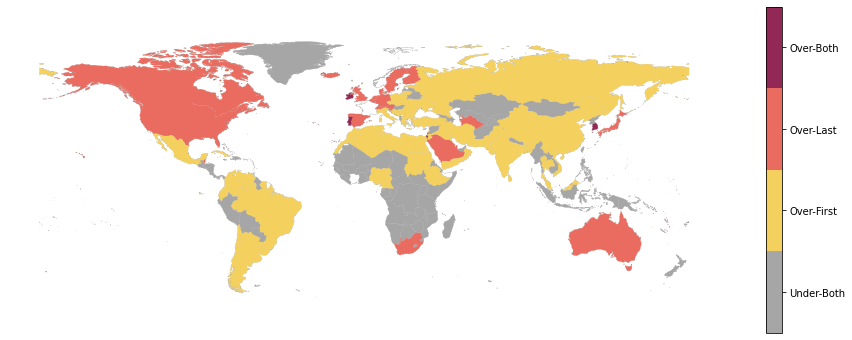

In [59]:
fig, ax=plt.subplots(figsize=(16,6))
world_geo.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
ax.axis("off")
df = cntry_meta.merge(world_geo,left_on='Code',right_on='ISO_A3')
df = gp.GeoDataFrame(df)
df.plot(column='g', cmap=cmap, norm=norm,vmin=0.9, vmax=1.1, ax=ax)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = fig.colorbar(sm,ticks=[0.5,1.5,2.5,3.5])
cbar.set_ticklabels(['Under-Both','Over-First','Over-Last','Over-Both'])
plt.savefig("Authorship-NullModel.png",bbox_inches='tight')

In [62]:
def plot_worldmap(fig, ax, outline, df, column,cmap,norm,vmin,vmax,ticks,tlabels,legend=False):
    outline.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
    ax.axis('off')
    df.plot(column=column, cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, ax=ax)
    if legend==True:
        sm=plt.cm.ScalarMappable(cmap=cmap,norm=norm)
        cbar=fig.colorbar(sm,ticks=ticks)
        cbar.set_ticklabels(tlabels)
    return fig, ax, cbar

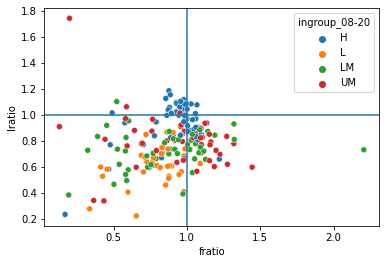

In [122]:
sns.scatterplot(x='fratio',y='lratio',data=cntry_meta,hue='ingroup_08-20')
plt.axhline(y=1)
plt.axvline(x=1)